# Step 3: Performance Analysis

**Aim:** calculate the important performance numbers (KPIs) for every plant, give each plant a **score from 0 to 100**, and find the best and weakest plants.

**KPI = Key Performance Indicator**, a number that tells how well something is working.

**Formulas used (all are simple)**

| KPI | Formula |
|---|---|
| Total energy | sum of Energy_Generated_MWh |
| Average daily generation | total energy / number of days |
| Capacity utilization rate (%) | total energy / (capacity x 4 hours x number of records) x 100 |
| Plant efficiency rate (%) | average of Efficiency_Percent |
| Availability rate (%) | average of Availability_Percent |
| Downtime rate (%) | total downtime hours / (4 hours x number of records) x 100 |
| Cost per MWh | (operating cost + maintenance cost) / total energy |
| Maintenance cost per MWh | maintenance cost / total energy |
| Revenue per MWh | total revenue / total energy |
| Profit margin (%) | (revenue - operating cost - maintenance cost) / revenue x 100 |

## Load the tools and the cleaned data

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt

# Folder where all the project files are kept
FOLDER = r"D:\RENEWABLE ENERGY PERFORMANCE Project"
if not os.path.exists(FOLDER):
    FOLDER = os.path.dirname(os.getcwd())      # if that folder is not found, use the folder above this notebook

DATA_FOLDER = os.path.join(FOLDER, "data")     # the CSV files are in the "data" folder
if not os.path.exists(DATA_FOLDER):
    DATA_FOLDER = FOLDER                        # if there is no "data" folder, they are in the main folder

cleaned_file = os.path.join(DATA_FOLDER, "cleaned_energy_data.csv")

df = pd.read_csv(cleaned_file)
df["Date"] = pd.to_datetime(df["Date"])
print("Rows:", len(df))

Rows: 52560


## 1. KPIs for every plant
`groupby` puts the rows of one plant together. `agg` then calculates a number for each group.

In [2]:
plant = df.groupby(["Plant_ID", "Plant_Name", "Energy_Type", "Region", "Installed_Capacity_MW"]).agg(
    Records=("Record_ID", "count"),
    Days=("Date", "nunique"),
    Total_Energy_MWh=("Energy_Generated_MWh", "sum"),
    Plant_Efficiency_Rate=("Efficiency_Percent", "mean"),
    Plant_Availability_Rate=("Availability_Percent", "mean"),
    Total_Downtime_Hours=("Downtime_Hours", "sum"),
    Operating_Cost=("Operating_Cost", "sum"),
    Maintenance_Cost=("Maintenance_Cost", "sum"),
    Revenue=("Revenue", "sum"),
).reset_index()

plant["Avg_Daily_Generation_MWh"] = plant["Total_Energy_MWh"] / plant["Days"]
plant["Capacity_Utilization_Rate"] = plant["Total_Energy_MWh"] / (plant["Installed_Capacity_MW"] * 4 * plant["Records"]) * 100
plant["Downtime_Rate"] = plant["Total_Downtime_Hours"] / (4 * plant["Records"]) * 100
plant["Cost_per_MWh"] = (plant["Operating_Cost"] + plant["Maintenance_Cost"]) / plant["Total_Energy_MWh"]
plant["Maintenance_Cost_per_MWh"] = plant["Maintenance_Cost"] / plant["Total_Energy_MWh"]
plant["Revenue_per_MWh"] = plant["Revenue"] / plant["Total_Energy_MWh"]
plant["Profit_Margin_Pct"] = (plant["Revenue"] - plant["Operating_Cost"] - plant["Maintenance_Cost"]) / plant["Revenue"] * 100

plant[["Plant_Name", "Energy_Type", "Total_Energy_MWh", "Capacity_Utilization_Rate", "Plant_Efficiency_Rate",
       "Plant_Availability_Rate", "Cost_per_MWh", "Maintenance_Cost_per_MWh", "Profit_Margin_Pct"]].round(2).head(10)

,Plant_Name,Energy_Type,Total_Energy_MWh,Capacity_Utilization_Rate,Plant_Efficiency_Rate,Plant_Availability_Rate,Cost_per_MWh,Maintenance_Cost_per_MWh,Profit_Margin_Pct
0,Sunridge Solar Park,Solar,445346.60,20.34,89.33,97.27,685.01,10.91,77.53
1,Helios Solar Farm,Solar,303699.03,17.33,87.12,95.62,850.06,21.62,72.59
2,Aditya Solar Park,Solar,235557.64,17.93,86.18,95.75,821.57,20.06,72.62
3,Suryakiran Solar Plant,Solar,278932.66,17.69,88.10,96.13,807.74,19.12,74.36
4,Dhoop Solar Park,Solar,196520.55,18.69,84.02,95.44,829.14,22.71,74.09
5,Marusthal Solar Farm,Solar,278738.14,19.89,88.24,96.56,725.10,15.00,75.81
6,Prabha Solar Park,Solar,212836.90,17.35,85.26,97.02,857.83,14.56,72.32
7,Kiran Solar Plant,Solar,71958.74,13.69,74.75,91.34,1255.47,58.83,61.37
8,Ujjwal Solar Plant,Solar,118755.99,16.95,82.16,95.47,936.40,24.30,70.73
9,Tejas Solar Park,Solar,135646.61,17.21,82.96,94.34,902.86,29.02,70.85


## 2. Plant Performance Score (0 to 100)
We want one number that tells how good a plant is. We use five parts and give each part a weight:

| Part | Weight | Better when |
|---|---|---|
| Capacity utilization | 30% | higher |
| Efficiency | 25% | higher |
| Availability | 20% | higher |
| Cost per MWh | 15% | **lower** |
| Profit margin | 10% | higher |

**Fair comparison:** solar, wind and hydro are very different, so we compare a plant only with plants of **its own type**.
Inside each type, the best plant gets 100 and the worst gets 0 for that part. This is called *min-max scaling*:

`scaled value = (value - minimum) / (maximum - minimum) x 100`

In [3]:
def scale_0_to_100(values):
    return (values - values.min()) / (values.max() - values.min()) * 100

# scale every part inside its own energy type
plant["Utilization_Score"] = plant.groupby("Energy_Type")["Capacity_Utilization_Rate"].transform(scale_0_to_100)
plant["Efficiency_Score"] = plant.groupby("Energy_Type")["Plant_Efficiency_Rate"].transform(scale_0_to_100)
plant["Availability_Score"] = plant.groupby("Energy_Type")["Plant_Availability_Rate"].transform(scale_0_to_100)
plant["Cost_Score"] = 100 - plant.groupby("Energy_Type")["Cost_per_MWh"].transform(scale_0_to_100)    # lower cost is better
plant["Margin_Score"] = plant.groupby("Energy_Type")["Profit_Margin_Pct"].transform(scale_0_to_100)

plant["Performance_Score"] = (0.30 * plant["Utilization_Score"]
                              + 0.25 * plant["Efficiency_Score"]
                              + 0.20 * plant["Availability_Score"]
                              + 0.15 * plant["Cost_Score"]
                              + 0.10 * plant["Margin_Score"])

plant[["Plant_Name", "Energy_Type", "Utilization_Score", "Efficiency_Score", "Availability_Score",
       "Cost_Score", "Margin_Score", "Performance_Score"]].round(1).head(8)

,Plant_Name,Energy_Type,Utilization_Score,Efficiency_Score,Availability_Score,Cost_Score,Margin_Score,Performance_Score
0,Sunridge Solar Park,Solar,100.0,100.0,100.0,100.0,100.0,100.0
1,Helios Solar Farm,Solar,54.8,84.8,72.1,71.1,69.5,69.7
2,Aditya Solar Park,Solar,63.7,78.4,74.4,76.1,69.6,72.0
3,Suryakiran Solar Plant,Solar,60.2,91.6,80.8,78.5,80.4,76.9
4,Dhoop Solar Park,Solar,75.3,63.6,69.1,74.7,78.7,71.4
5,Marusthal Solar Farm,Solar,93.3,92.5,88.1,93.0,89.4,91.6
6,Prabha Solar Park,Solar,55.1,72.1,95.8,69.7,67.7,70.9
7,Kiran Solar Plant,Solar,0.0,0.0,0.0,0.0,0.0,0.0


## 3. Rank the plants and give a class
- **Rank** 1 = best score.
- **Class:** the best quarter of the plants (score at or above the 75th percentile) = **High**, the weakest quarter (at or below the 25th percentile) = **Low**, all others = **Medium**.

In [4]:
plant["Rank_Overall"] = plant["Performance_Score"].rank(ascending=False, method="min").astype(int)
plant["Rank_in_Type"] = plant.groupby("Energy_Type")["Performance_Score"].rank(ascending=False, method="min").astype(int)

low_limit = plant["Performance_Score"].quantile(0.25)     # 25% of the plants score below this
high_limit = plant["Performance_Score"].quantile(0.75)    # 25% of the plants score above this

def give_class(score):
    if score >= high_limit:
        return "High"
    elif score <= low_limit:
        return "Low"
    else:
        return "Medium"

plant["Performance_Class"] = plant["Performance_Score"].apply(give_class)

plant = plant.sort_values(["Rank_Overall", "Plant_ID"]).reset_index(drop=True)
print(plant["Performance_Class"].value_counts())
plant[["Rank_Overall", "Plant_Name", "Energy_Type", "Performance_Score", "Performance_Class"]].round(2).head(10)

Performance_Class
Medium    12
High       6
Low        6
Name: count, dtype: int64


,Rank_Overall,Plant_Name,Energy_Type,Performance_Score,Performance_Class
0,1,Sunridge Solar Park,Solar,100.00,High
1,1,Vayu Wind Farm,Wind,100.00,High
2,3,Ganga Setu Hydro Plant,Hydro,95.54,High
3,4,Marut Wind Park,Wind,93.34,High
4,5,Marusthal Solar Farm,Solar,91.60,High
5,6,Pavan Wind Park,Wind,85.49,High
6,7,Neerja Hydro Station,Hydro,82.87,Medium
7,8,Himalaya Hydro Plant,Hydro,80.27,Medium
8,9,Suryakiran Solar Plant,Solar,76.92,Medium
9,10,Samir Wind Farm,Wind,76.37,Medium


### Top 10 plants

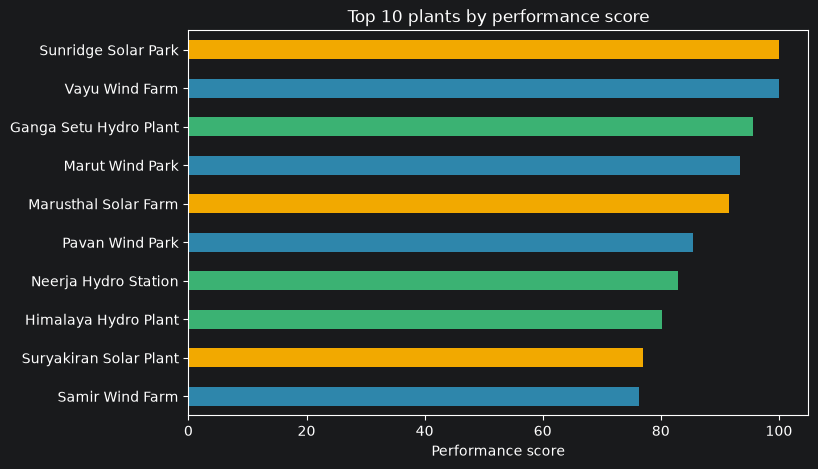

In [5]:
top10 = plant.head(10).sort_values("Performance_Score")

top10.plot(kind="barh", x="Plant_Name", y="Performance_Score", legend=False, figsize=(8, 5),
           color=top10["Energy_Type"].map({"Solar": "#F2A900", "Wind": "#2E86AB", "Hydro": "#3BB273"}))
plt.title("Top 10 plants by performance score")
plt.xlabel("Performance score")
plt.ylabel("")
plt.show()

**What we see:** **Sunridge Solar Park** and **Vayu Wind Farm** both score **100**, because each is the best plant of its own type. **Ganga Setu Hydro Plant** is the best hydro plant (95.5). Remember that the score compares plants inside the same type, so it shows who is best among solar, among wind and among hydro.

### Weakest 6 plants

In [6]:
weakest = plant.tail(6)[["Rank_Overall", "Plant_Name", "Energy_Type", "Performance_Score", "Downtime_Rate", "Cost_per_MWh"]]
weakest.round(2)

,Rank_Overall,Plant_Name,Energy_Type,Performance_Score,Downtime_Rate,Cost_per_MWh
18,19,Brahma Hydro Station,Hydro,51.43,4.39,359.41
19,20,Anil Wind Farm,Wind,41.22,7.12,830.66
20,21,Vata Wind Park,Wind,18.55,7.83,1106.71
21,22,Kiran Solar Plant,Solar,0.00,8.66,1255.47
22,22,Sagar Pavan Wind Farm,Wind,0.00,9.08,1320.97
23,22,Nadi Hydro Station,Hydro,0.00,6.14,434.27


**What we see:** The **6 plants in the Low class** are Brahma Hydro, Anil Wind, Vata Wind, Kiran Solar, Sagar Pavan Wind and Nadi Hydro. Five of them are the plants with the highest downtime. High downtime lowers utilization and availability and raises cost per MWh, so these plants lose points in several parts at the same time. There are 6 High, 12 Medium and 6 Low plants.

## 4. Energy type comparison

In [7]:
by_type = df.groupby("Energy_Type").agg(
    Plants=("Plant_ID", "nunique"),
    Total_Energy_MWh=("Energy_Generated_MWh", "sum"),
    Efficiency=("Efficiency_Percent", "mean"),
    Availability=("Availability_Percent", "mean"),
    Operating_Cost=("Operating_Cost", "sum"),
    Maintenance_Cost=("Maintenance_Cost", "sum"),
    Revenue=("Revenue", "sum"),
    Max_Energy=("Installed_Capacity_MW", lambda x: x.sum() * 4),    # sum of capacity x 4 hours over all records
)
by_type["Capacity_Utilization_Rate"] = by_type["Total_Energy_MWh"] / by_type["Max_Energy"] * 100
by_type["Cost_per_MWh"] = (by_type["Operating_Cost"] + by_type["Maintenance_Cost"]) / by_type["Total_Energy_MWh"]
by_type["Profit_Margin_Pct"] = (by_type["Revenue"] - by_type["Operating_Cost"] - by_type["Maintenance_Cost"]) / by_type["Revenue"] * 100

by_type = by_type.loc[["Solar", "Wind", "Hydro"]]
by_type[["Plants", "Total_Energy_MWh", "Capacity_Utilization_Rate", "Efficiency", "Availability", "Cost_per_MWh", "Profit_Margin_Pct"]].round(2)

,Plants,Total_Energy_MWh,Capacity_Utilization_Rate,Efficiency,Availability,Cost_per_MWh,Profit_Margin_Pct
Energy_Type,,,,,,,
Solar,10,2277992.85,18.18,84.81,95.49,813.75,73.68
Wind,8,4469718.68,40.50,86.77,93.97,583.93,82.56
Hydro,6,3057303.77,37.13,85.99,95.80,338.88,91.91


**What we see:** Wind gives the most energy and the highest utilization (40.5%). Hydro has the lowest cost per MWh (INR 339) and the best profit margin. Solar has the lowest utilization (18.2%) and the highest cost per MWh.

## 5. High capacity but low generation
These are big plants that make less energy than the usual plant of their own type. A big plant that is used badly wastes a lot of money, so we check them first.

**Rule (same as MySQL Q10):** capacity is at least the **average** capacity of all plants (151.25 MW) **and** utilization is below the **average** utilization of its own energy type.

In [8]:
avg_capacity = plant["Installed_Capacity_MW"].mean()
type_avg_utilization = plant.groupby("Energy_Type")["Capacity_Utilization_Rate"].transform("mean")

big_plant = plant["Installed_Capacity_MW"] >= avg_capacity
below_avg = plant["Capacity_Utilization_Rate"] < type_avg_utilization

flagged = plant[big_plant & below_avg].copy()
flagged["Type_Avg_Utilization"] = type_avg_utilization[flagged.index]
flagged["Gap_in_Points"] = flagged["Capacity_Utilization_Rate"] - flagged["Type_Avg_Utilization"]
flagged["Shortfall_MWh"] = (flagged["Type_Avg_Utilization"] - flagged["Capacity_Utilization_Rate"]) / 100 * (flagged["Installed_Capacity_MW"] * 4 * flagged["Records"])

flagged[["Plant_ID", "Plant_Name", "Energy_Type", "Installed_Capacity_MW", "Capacity_Utilization_Rate",
         "Type_Avg_Utilization", "Gap_in_Points", "Shortfall_MWh"]].round(2)

,Plant_ID,Plant_Name,Energy_Type,Installed_Capacity_MW,Capacity_Utilization_Rate,Type_Avg_Utilization,Gap_in_Points,Shortfall_MWh
1,P002,Helios Solar Farm,Solar,200,17.33,17.71,-0.37,6518.7
3,P004,Suryakiran Solar Plant,Solar,180,17.69,17.71,-0.02,263.3


**What we see:** **Helios Solar Farm** (200 MW, 17.33% vs 17.91% solar average) and **Suryakiran Solar Plant** (180 MW, 17.69% vs 17.91% solar average) are the two large plants running slightly below their energy type's average utilization (matching MySQL query Q10). The gaps are very small (0.2 to 0.6 percentage points), so no large plant is a serious problem.

## 6. Money lost because of downtime
When a plant is down, it cannot sell energy. We estimate the lost energy like this:

`energy lost = energy / (availability / 100) - energy`

This is a **minimum** estimate: we skip the blocks where availability was 0% (a full shutdown), because we cannot calculate from zero. The money lost is `energy lost x revenue per MWh of that plant`.

Total energy lost (MWh): 333835
Total money lost (crore): 118.2


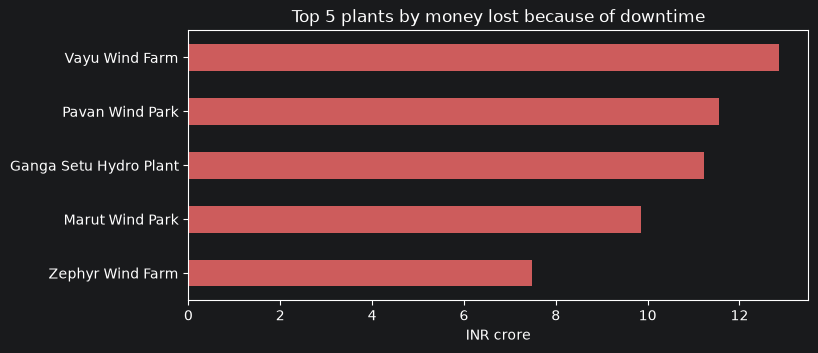

In [9]:
df["Lost_Energy_MWh"] = 0.0
working = df["Availability_Percent"] > 0
df.loc[working, "Lost_Energy_MWh"] = df["Energy_Generated_MWh"] / (df["Availability_Percent"] / 100) - df["Energy_Generated_MWh"]

lost = df.groupby("Plant_Name")["Lost_Energy_MWh"].sum().reset_index()
lost = lost.merge(plant[["Plant_Name", "Revenue_per_MWh"]], on="Plant_Name")
lost["Lost_Revenue_Crore"] = lost["Lost_Energy_MWh"] * lost["Revenue_per_MWh"] / 10000000
lost = lost.sort_values("Lost_Revenue_Crore", ascending=False)

print("Total energy lost (MWh):", round(lost["Lost_Energy_MWh"].sum()))
print("Total money lost (crore):", round(lost["Lost_Revenue_Crore"].sum(), 1))

top5 = lost.head(5).sort_values("Lost_Revenue_Crore")
top5.plot(kind="barh", x="Plant_Name", y="Lost_Revenue_Crore", legend=False, color="indianred", figsize=(8, 3.5))
plt.title("Top 5 plants by money lost because of downtime")
plt.xlabel("INR crore")
plt.ylabel("")
plt.show()

**What we see:** About **334,000 MWh** of energy and at least **INR 118 crore** was lost because of downtime. The biggest losses are in big plants: Vayu Wind Farm (INR 12.9 crore) and Pavan Wind Park (INR 11.6 crore). A big plant loses more money for the same downtime, so even a small downtime in a big plant is expensive.

## 7. Monthly summary

In [10]:
df["Month"] = df["Date"].dt.month

monthly = df.groupby(["Month", "Energy_Type"]).agg(
    Energy_MWh=("Energy_Generated_MWh", "sum"),
    Avg_Efficiency=("Efficiency_Percent", "mean"),
    Avg_Availability=("Availability_Percent", "mean"),
    Operating_Cost=("Operating_Cost", "sum"),
    Maintenance_Cost=("Maintenance_Cost", "sum"),
    Revenue=("Revenue", "sum"),
).reset_index()
monthly["Cost_per_MWh"] = (monthly["Operating_Cost"] + monthly["Maintenance_Cost"]) / monthly["Energy_MWh"]

monthly.round(2).head(6)

,Month,Energy_Type,Energy_MWh,Avg_Efficiency,Avg_Availability,Operating_Cost,Maintenance_Cost,Revenue,Cost_per_MWh
0,1,Hydro,178427.76,85.08,95.35,8.199051e+07,4234014.21,7.471910e+08,483.25
1,1,Solar,201110.13,86.24,95.50,1.538631e+08,3824459.89,6.219185e+08,784.09
2,1,Wind,330444.45,86.83,94.77,2.110830e+08,7343844.82,1.109232e+09,661.01
3,2,Hydro,156164.16,84.90,95.76,7.382491e+07,3426123.04,6.542880e+08,494.68
4,2,Solar,182710.87,85.59,95.92,1.389619e+08,4045017.08,5.654186e+08,782.70
5,2,Wind,293514.38,86.67,93.26,1.903409e+08,7960892.17,9.815890e+08,675.61


## 8. Check the key numbers
These numbers must be the **same** in Python, MySQL, Power BI and Streamlit. If one tool shows a different number, something is wrong in that tool.

In [11]:
print("Records                  :", len(df))
print("Total energy (MWh)        :", round(df["Energy_Generated_MWh"].sum(), 3))
print("Total revenue (crore)     :", round(df["Revenue"].sum() / 10000000, 1))
print("Operating cost (crore)    :", round(df["Operating_Cost"].sum() / 10000000, 1))
print("Maintenance cost (crore)  :", round(df["Maintenance_Cost"].sum() / 10000000, 1))
print("Average efficiency (%)    :", round(df["Efficiency_Percent"].mean(), 2))
print("Overall utilization (%)   :", round(df["Energy_Generated_MWh"].sum() / (df["Installed_Capacity_MW"] * 4).sum() * 100, 2), " (energy / maximum energy)")
print("Average of Capacity_Utilization column (%):", round(df["Capacity_Utilization"].mean(), 2))
print("Total installed capacity  :", plant["Installed_Capacity_MW"].sum(), "MW")

Records                  : 52560
Total energy (MWh)        : 9805015.292
Total revenue (crore)     : 3481.3
Operating cost (crore)    : 531.5
Maintenance cost (crore)  : 18.4
Average efficiency (%)    : 85.76
Overall utilization (%)   : 30.83  (energy / maximum energy)
Average of Capacity_Utilization column (%): 28.68
Total installed capacity  : 3630 MW


## 9. Final insights
1. **Vayu Wind Farm** gives the most energy (1,270 GWh). Wind is the top energy type.
2. Each type has one best plant (Sunridge Solar Park, Vayu Wind Farm, Ganga Setu Hydro Plant). They lead their own types in the performance score.
3. **Hydro is the cheapest** to run (INR 339 per MWh). **Solar is the most costly** (INR 814 per MWh).
4. Five of the six Low-class plants are the plants with the highest downtime. Fixing downtime is the fastest way to improve results.
5. Downtime cost the company at least **INR 118 crore**, mostly in large wind and hydro plants.
6. No big plant is a serious problem. The two big plants below their type average in Q10 (Helios Solar Farm and Suryakiran Solar Plant) are only 0.2 to 0.6 points behind.
7. The best months are July to September. Maintenance should be planned in the low months (January to April), when losing a day costs less.